In [12]:
"""
Model Training Notebook

Divisão de dados
Treinamento: 2003 - 2016
Validação: 2016 - 2020
Testes: 2020 -  2023
"""

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.linear_model import (
    fit_linear_regression,
    predict_linear_regression
)

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.data_prep import load_flight_data

df = load_flight_data(
    "../data/raw/air traffic-selected-columns.csv"
)

In [13]:
def create_lagged_series(K, series):

    X = []
    y = []

    for i in range(K, len(series)):
        X.append(series[i-K:i])
        y.append(series[i])

    return np.array(X), np.array(y)

In [14]:
series = df["Flt"].to_numpy()

K_values = list(range(1, 25))
rmse_values = []

for K in K_values:

    X, y = create_lagged_series(K, series)

    target_dates = df["Date"].to_numpy()[K:]

    # Treino: 2003-2019
    train_mask = target_dates < np.datetime64("2020-01-01")

    # Validação: 2020-2021
    val_mask = (
        (target_dates >= np.datetime64("2020-01-01")) &
        (target_dates < np.datetime64("2022-01-01"))
    )

    # Teste: 2022-2023
    test_mask = target_dates >= np.datetime64("2022-01-01")

    X_train = X[train_mask]
    y_train = y[train_mask]

    X_val = X[val_mask]
    y_val = y[val_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    theta = fit_linear_regression(
        X_train,
        y_train
    )

    y_val_pred = predict_linear_regression(
        X_val,
        theta
    )

    errors_val = y_val - y_val_pred

    mse_val = np.mean(errors_val ** 2)
    rmse_val = np.sqrt(mse_val)

    rmse_values.append(rmse_val)

In [15]:
results = pd.DataFrame({
    "K": K_values,
    "RMSE_validation": rmse_values
})

results

best_index = np.argmin(rmse_values)

best_K = K_values[best_index]
best_rmse = rmse_values[best_index]

print(f"Melhor K: {best_K}")
print(f"Menor RMSE de validação: {best_rmse:.2f}")

Melhor K: 5
Menor RMSE de validação: 121371.61


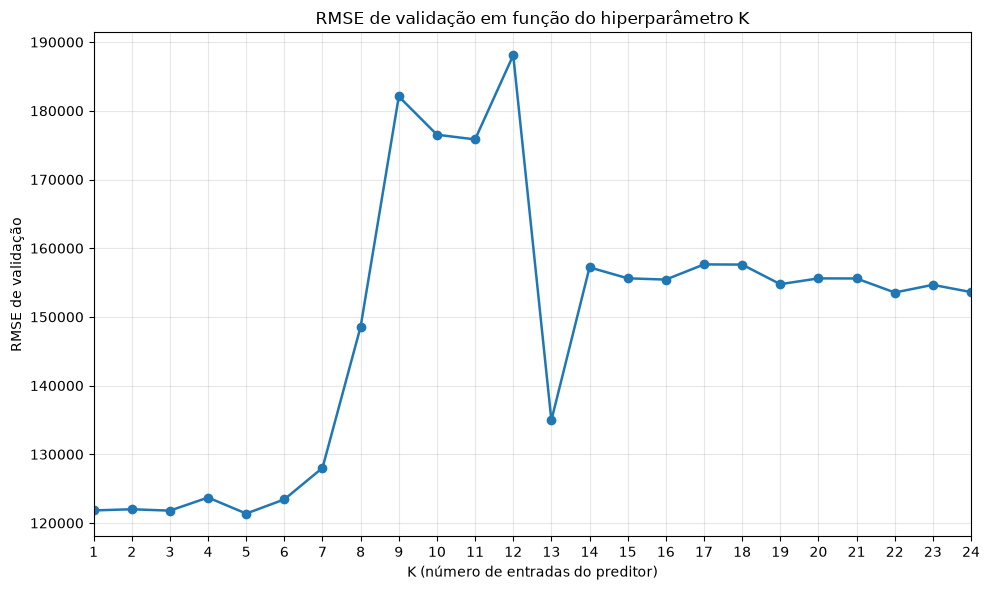

In [20]:
plt.figure(figsize=(10, 6))
ax = plt.gca()

# Curva RMSE x K
ax.plot(
    K_values,
    rmse_values,
    marker="o",
    linewidth=1.8
)

# Configurações dos eixos
ax.set_xticks(K_values)
ax.set_xlim(1, 24)

ax.set_xlabel("K (número de entradas do preditor)")
ax.set_ylabel("RMSE de validação")
ax.set_title("RMSE de validação em função do hiperparâmetro K")

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
best_K = 5

X, y = create_lagged_series(best_K, series)
target_dates = df["Date"].to_numpy()[best_K:]

train_mask = target_dates < np.datetime64("2022-01-01")
test_mask = target_dates >= np.datetime64("2022-01-01")

X_train_final = X[train_mask]
y_train_final = y[train_mask]
X_test = X[test_mask]
y_test = y[test_mask]

test_dates = target_dates[test_mask]

X_train_final_aug = np.column_stack([
    np.ones(len(X_train_final)),
    X_train_final
])

theta_final, residuals, rank, singular_values = np.linalg.lstsq(
    X_train_final_aug,
    y_train_final,
    rcond=None
)


In [22]:
X_test_aug = np.column_stack([
    np.ones(len(X_test)),
    X_test
])

y_test_pred = X_test_aug @ theta_final

errors_test = y_test - y_test_pred

mse_test = np.mean(errors_test ** 2)

rmse_test = np.sqrt(mse_test)

mape_test = np.mean(
    np.abs(
        (y_test - y_test_pred) / y_test
    )
) * 100

ss_res = np.sum(
    (y_test - y_test_pred) ** 2
)

ss_tot = np.sum(
    (y_test - np.mean(y_test)) ** 2
)

r2_test = 1 - (ss_res / ss_tot)

print(f"RMSE de teste: {rmse_test:.2f}")
print(f"MAPE de teste: {mape_test:.2f}%")
print(f"R² de teste: {r2_test:.4f}")

RMSE de teste: 38127.68
MAPE de teste: 4.21%
R² de teste: 0.2769


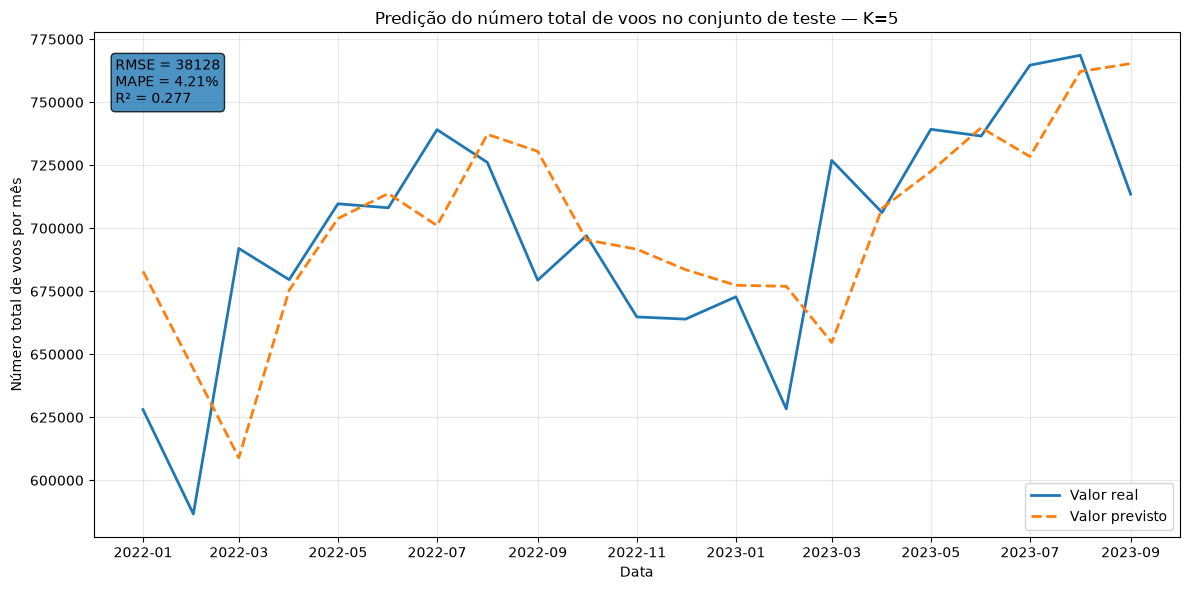

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_dates,
    y_test,
    label="Valor real",
    linewidth=2
)

plt.plot(
    test_dates,
    y_test_pred,
    label="Valor previsto",
    linewidth=2,
    linestyle="--"
)

plt.title(
    f"Predição do número total de voos no conjunto de teste — K={best_K}"
)

plt.xlabel("Data")
plt.ylabel("Número total de voos por mês")

plt.text(
    0.02,
    0.95,
    (
        f"RMSE = {rmse_test:.0f}\n"
        f"MAPE = {mape_test:.2f}%\n"
        f"R² = {r2_test:.3f}"
    ),
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        alpha=0.8
    )
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()